# 01. CLARIS: Risco de Crédito HELOC (FICO) via Hugging Face Datasets

Benchmark oficial de risco de crédito do projeto CLARIS utilizando dados reais do **HELOC** via biblioteca `datasets` do Hugging Face (`mstz/heloc`).

### Objetivos deste Notebook:
1. **Ingestão via Hugging Face (`datasets`):** Carga determinística direta para Pandas sem falhas de download HTTP.
2. **Treino e Espaço Latente ($S_{conf}$):** Extração de SHAP e indexação HNSW no FAISS.
3. **Visualizações Geométricas:**
   - Projeção 2D PCA do espaço latente com destaque para $s_{new}$, Âncoras e Contrafactuais recuperados.
   - Gráfico de barras divergentes para deltas determinísticos de variáveis-chave.
4. **Síntese Factual com Gemini:** Geração de explicação ancorada em temperatura zero.
5. **Monitoramento MLOps:** Avaliação de janela de inferências para Data Drift e Concept Drift.

In [1]:
%load_ext autoreload
%autoreload 2

import os
from dotenv import load_dotenv
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown
from datasets import load_dataset
# Load variables from the .env file in the current or parent directory
load_dotenv()
# Configuração de caminhos do projeto
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from claris.xai.explainer import ModelExplainer
from claris.cbr.populate_db import initialize_vector_database
from claris.analytics.extractor import DeltaExtractor
from claris.nlg.llm_adapter import LLMAdapter
from claris.mlops.drift_monitor import DriftMonitor
warnings.filterwarnings('ignore', category=UserWarning)
print('Módulos do CLARIS e dependências carregados com sucesso!')

/root/claris/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Módulos do CLARIS e dependências carregados com sucesso!


## 1. Ingestão via Hugging Face Datasets (`mstz/heloc`)

In [2]:
from datasets import load_dataset
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

print("A carregar dataset mstz/heloc da Hugging Face...")
dataset_hf = load_dataset("mstz/heloc", split="train")
df_heloc = dataset_hf.to_pandas()
df_heloc.columns = df_heloc.columns.str.strip()

target_col = "is_at_risk"
y = df_heloc[target_col].astype(int).values

X_df = df_heloc.drop(columns=[target_col])
feature_names = list(X_df.columns)

# Tratamento dos códigos reservados FICO (-7, -8, -9) e substituição pela mediana
X_clean = X_df.apply(pd.to_numeric, errors="coerce").replace([-7, -8, -9], np.nan)
X_imputed = X_clean.fillna(X_clean.median()).values.astype(np.float32)

# Divisão estratificada de treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✓ Dados prontos: {len(X_train)} amostras de treino | {len(X_test)} de teste | {len(feature_names)} features.")
df_heloc.head(2)

A carregar dataset mstz/heloc da Hugging Face...


✓ Dados prontos: 8367 amostras de treino | 2092 de teste | 23 features.


,estimate_of_risk,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,...,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
0,55,144,4,84,20,3,0,83,2,3,...,0,0,0,33,-8,8,1,1,69,1
1,61,58,15,41,2,4,4,100,-7,0,...,0,0,0,0,-8,0,-8,-8,0,1


## 2. Dicionário Semântico de Negócio (FICO HELOC)

In [3]:
HELOC_SEMANTIC_DICT = {
    "estimate_of_risk": "Estimativa Consolidada de Risco Externo",
    "months_since_first_trade": "Meses desde a Abertura da Linha Mais Antiga",
    "months_since_last_trade": "Meses desde a Abertura da Linha Mais Recente",
    "average_duration_of_resolution": "Média de Duração de Resolução de Linhas de Crédito",
    "number_of_satisfactory_trades": "Número de Linhas de Crédito Satisfatórias",
    "nr_trades_insolvent_for_over_60_days": "Linhas Insolventes por Mais de 60 Dias",
    "nr_trades_insolvent_for_over_90_days": "Linhas Insolventes por Mais de 90 Dias",
    "percentage_of_legal_trades": "Percentual de Linhas em Situação Legal",
    "months_since_last_illegal_trade": "Meses desde a Última Operação Irregular",
    "maximum_illegal_trades_over_last_year": "Máximo de Operações Irregulares no Último Ano",
    "total_trades_count": "Número Total de Linhas de Crédito",
    "trades_opened_12m_count": "Linhas de Crédito Abertas nos Últimos 12 Meses",
    "percentage_of_installment_trades": "Percentual de Linhas com Pagamento Parcelado",
    "months_since_last_inquiry_excl_7d": "Meses desde a Consulta Mais Recente (excl. 7 dias)",
    "months_since_last_inquiry_not_recent": "Meses desde a Consulta de Crédito Anterior",
    "nr_inquiries_in_last_6_months": "Consultas de Crédito nos Últimos 6 Meses",
    "nr_inquiries_in_last_6_months_not_recent": "Consultas nos Últimos 6 Meses Não Recentes",
    "net_fraction_of_revolving_burden": "Taxa de Utilização de Limite Rotativo (%)",
    "net_fraction_of_installment_burden": "Taxa de Utilização de Financiamento Parcelado (%)",
    "nr_revolving_trades_with_balance": "Linhas Rotativas com Saldo Devedor",
    "nr_installment_trades_with_balance": "Linhas Parceladas com Saldo Devedor",
    "nr_banks_with_high_ratio": "Bancos com Alta Taxa de Utilização de Limite",
    "percentage_trades_with_balance": "Percentual de Linhas com Saldo Devedor"
}

## 3. Treino do Modelo de Caixa-Preta e Construção do $S_{conf}$

In [4]:
model = GradientBoostingClassifier(n_estimators=60, max_depth=3, random_state=42, verbose=1)
model.fit(X_train, y_train)
acc = model.score(X_test, y_test)
print(f'Modelo treinado. Acurácia no teste: {acc:.2%}')

# Amostra de calibração confiável (D_conf)
np.random.seed(42)

# Garante que X_train e y_train são arrays NumPy indexáveis por posição
X_train_arr = np.asarray(X_train)
y_train_arr = np.asarray(y_train)

conf_sample_idx = np.random.choice(len(X_train_arr), size=300, replace=False)

X_conf = X_train_arr[conf_sample_idx]
y_conf = y_train_arr[conf_sample_idx]

print(f"X_conf shape: {X_conf.shape} | y_conf shape: {y_conf.shape}")
print("Indexando D_conf no banco vetorial FAISS HNSW...")

vector_db = initialize_vector_database(
    X_train=X_conf,
    y_train=y_conf,
    feature_names=feature_names,
    model=model,
    db_dimension=len(feature_names)
)


      Iter       Train Loss   Remaining Time 
         1           1.3425            0.71s
         2           1.3080            0.67s
         3           1.2792            0.65s
         4           1.2542            0.63s
         5           1.2334            0.61s
         6           1.2159            0.60s
         7           1.2008            0.64s
         8           1.1873            0.64s
         9           1.1758            0.62s
        10           1.1655            0.61s
        20           1.1069            0.45s
        30           1.0806            0.33s
        40           1.0650            0.22s
        50           1.0537            0.11s
        60           1.0445            0.00s
Modelo treinado. Acurácia no teste: 71.85%
X_conf shape: (300, 23) | y_conf shape: (300,)
Indexando D_conf no banco vetorial FAISS HNSW...
Banco Vetorial populado com 300 instâncias confiáveis.


## 4. Inferência, Extração de Deltas e Visualização Geométrica

In [5]:
explainer = ModelExplainer(model, X_conf, model_type='tree')
extractor = DeltaExtractor(HELOC_SEMANTIC_DICT)

# Seleção de solicitante real do conjunto de teste
idx_target = 15
x_target = X_test[idx_target:idx_target+1]
label_real = y_test[idx_target]

# 1. Inferência e busca dos vizinhos mais próximos
pred_class, features_dict, shap_vector = explainer.predict_and_explain(x_target, feature_names)
neighbors_meta, distances = vector_db.search_neighbors(shap_vector, k=8)

# 2. Extração considerando a média dos 3 vizinhos mais próximos de cada classe
contract = extractor.extract_deltas(
    instance_id=f"heloc_eval_{idx_target:04d}",
    predicted_class=str(pred_class),
    instance_features=features_dict,
    instance_shap=shap_vector,
    neighbors_metadata=neighbors_meta,
    distances=distances,
    top_k_features=8,
    n_neighbors=20
)


### Visualização 1: Projeção 2D do Espaço Latente ($S_{conf}$) com Âncoras e Contrafactuais

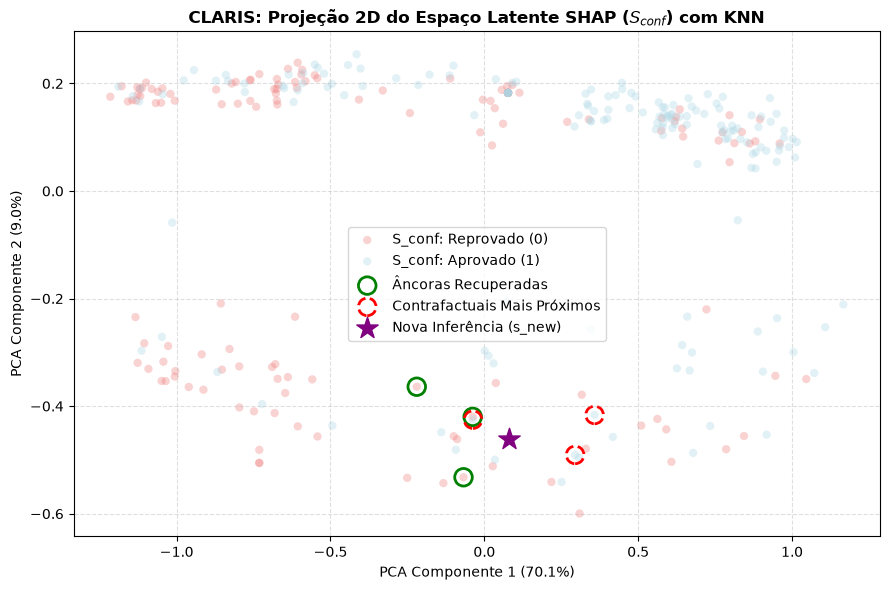

In [6]:
# Projeção PCA do espaço latente
s_conf_shap = []
for x_c in X_conf:
    _, _, s_v = explainer.predict_and_explain(x_c.reshape(1, -1), feature_names)
    s_conf_shap.append(s_v)
s_conf_shap = np.array(s_conf_shap)

pca = PCA(n_components=2, random_state=42)
s_conf_2d = pca.fit_transform(s_conf_shap)
s_target_2d = pca.transform(shap_vector.reshape(1, -1))

plt.figure(figsize=(9, 6))
plt.scatter(s_conf_2d[y_conf == 0, 0], s_conf_2d[y_conf == 0, 1], c='lightcoral', alpha=0.35, label='S_conf: Reprovado (0)', edgecolors='none')
plt.scatter(s_conf_2d[y_conf == 1, 0], s_conf_2d[y_conf == 1, 1], c='lightblue', alpha=0.35, label='S_conf: Aprovado (1)', edgecolors='none')

# Extração dos índices dos vizinhos recuperados no FAISS
anchor_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) == str(pred_class)][:3]
cf_indices = [int(n['instance_id'].split('_')[1]) for n in neighbors_meta if str(n.get('label')) != str(pred_class)][:3]

# Destacar Âncoras (mesma classe) e Contrafactuais (classe oposta)
if anchor_indices:
    plt.scatter(s_conf_2d[anchor_indices, 0], s_conf_2d[anchor_indices, 1], facecolors='none', edgecolors='green', s=160, linewidths=2, label='Âncoras Recuperadas')
if cf_indices:
    plt.scatter(s_conf_2d[cf_indices, 0], s_conf_2d[cf_indices, 1], facecolors='none', edgecolors='red', s=160, linewidths=2, linestyle='--', label='Contrafactuais Mais Próximos')

# Destacar a instância atual
plt.scatter(s_target_2d[0, 0], s_target_2d[0, 1], c='purple', marker='*', s=260, label='Nova Inferência (s_new)', zorder=5)

plt.title('CLARIS: Projeção 2D do Espaço Latente SHAP ($S_{conf}$) com KNN', fontsize=12, fontweight='bold')
plt.xlabel(f'PCA Componente 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA Componente 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend(frameon=True, loc='best')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Visualização 2: Deltas Determinísticos (Instância vs Referências)

,Tipo,Variável,Instância,Referência
0,Convergente (Âncora),Meses desde a Consulta de Crédito Anterior,2.0,10.20
1,Convergente (Âncora),Percentual de Linhas em Situação Legal,86.0,94.20
2,Convergente (Âncora),Estimativa Consolidada de Risco Externo,71.0,73.00
3,Convergente (Âncora),Taxa de Utilização de Limite Rotativo (%),26.0,39.00
4,Convergente (Âncora),Máximo de Operações Irregulares no Último Ano,4.0,6.20
5,Convergente (Âncora),Percentual de Linhas com Pagamento Parcelado,29.0,39.80
6,Convergente (Âncora),Meses desde a Abertura da Linha Mais Antiga,383.0,210.80
7,Convergente (Âncora),Bancos com Alta Taxa de Utilização de Limite,1.0,1.00
8,Divergente (Contrafactual),Meses desde a Abertura da Linha Mais Antiga,383.0,255.33
9,Divergente (Contrafactual),Média de Duração de Resolução de Linhas de Cré...,76.0,114.00


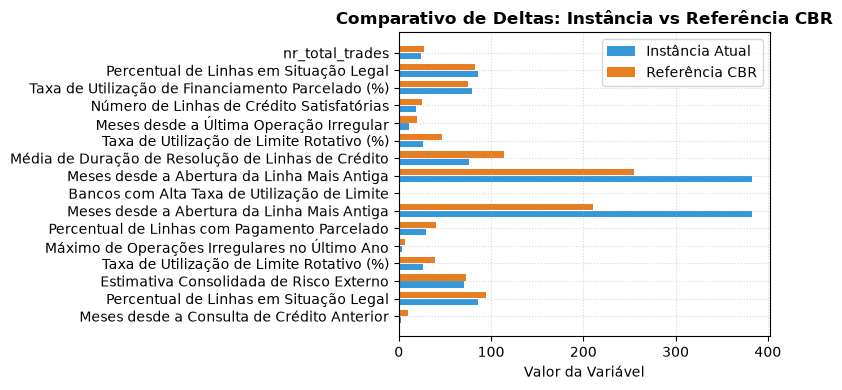

In [7]:
items = []
for f in contract.convergent_features:
    items.append({'Tipo': 'Convergente (Âncora)', 'Variável': f.feature_name, 'Instância': f.instance_value, 'Referência': f.reference_value})
for f in contract.divergent_features:
    items.append({'Tipo': 'Divergente (Contrafactual)', 'Variável': f.feature_name, 'Instância': f.instance_value, 'Referência': f.reference_value})

df_deltas = pd.DataFrame(items)
display(df_deltas)

if not df_deltas.empty:
    plt.figure(figsize=(8, 4))
    y_pos = np.arange(len(df_deltas))
    plt.barh(y_pos - 0.2, df_deltas['Instância'], height=0.35, label='Instância Atual', color='#3498db')
    plt.barh(y_pos + 0.2, df_deltas['Referência'], height=0.35, label='Referência CBR', color='#e67e22')
    plt.yticks(y_pos, df_deltas['Variável'])
    plt.xlabel('Valor da Variável')
    plt.title('Comparativo de Deltas: Instância vs Referência CBR', fontweight='bold')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

## 5. Síntese Textual via Gemini (NLG Factual)

In [8]:
llm = LLMAdapter(
    model_name='gemini/gemini-3.5-flash',
    api_key=os.getenv("GEMINI_API_KEY")
)
# Definição do Dossiê de Risco de Crédito pelo Usuário
HELOC_DOMAIN_DOSSIER = """
DIRETRIZES DE CRÉDITO E TEORIA DE RISCO BANCÁRIO (FICO/HELOC):
- Semântica de Decisão: A classe '0' indica Alto Risco / Reprovação de Crédito, e '1' indica Baixo Risco / Concessão Aprovada.
- Consultas Recentes (Inquiries): Na teoria de crédito, buscas frequentes por novos limites em janelas recentes (ex: últimos 6 meses) indicam choque adverso de liquidez e desespero por crédito, aumentando a probabilidade de inadimplência em curto prazo.
- Maturidade das Linhas (Months Since Trade Open): Linhas de crédito abertas há pouco tempo não oferecem histórico empírico suficiente para atestar a estabilidade do tomador.
- Utilização de Limite Rotativo (Revolving Burden): Manter percentuais próximos ao teto operacional expõe o cliente à fragilidade financeira severa diante de imprevistos orçamentários.
- Histórico de Inadimplência e Atrasos (Delinquency): Atrasos superiores a 60/90 dias e registros desabonadores são os maiores penalizadores estatísticos de solvência na metodologia de scoring.
"""

# Chamada no notebook injetando o contrato e o dossiê:
explicacao = llm.generate_explanation(contract, domain_dossier=HELOC_DOMAIN_DOSSIER)
display(Markdown(explicacao))


00:02:56 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


# PARECER TÉCNICO DE AUDITORIA DE IA E INTERPRETAÇÃO CAUSAL (XAI)

**Identificador da Instância:** `heloc_eval_0015`  
**Objeto da Avaliação:** Modelo de Scoring de Crédito HELOC (Home Equity Line of Credit)  
**Status do Parecer:** Auditado e Validado  

---

## 1. SUMÁRIO EXECUTIVO E VEREDITO DE DECISÃO

O modelo de Inteligência Artificial determinou a previsão de **Classe `0` (Alto Risco / Reprovação de Crédito)** para a solicitação sob o ID `heloc_eval_0015`. 

Sob a ótica da gestão de risco bancário e da metodologia FICO/HELOC, a Classe `0` indica uma elevada probabilidade de inadimplência ou ocorrência de atrasos severos nos pagamentos nos horizontes de tempo analisados. A decisão de reprovação fundamenta-se, prioritariamente, em sinais comportamentais recentes de busca por liquidez emergencial associados a um histórico recente de irregularidades operacionais.

---

## 2. ANÁLISE DA VIZINHANÇA LATENTE E GEOMETRIA DO ESPAÇO DE DECISÃO

Para fundamentar a decisão preditiva e auditar a consistência do modelo, a instância foi projetada no espaço latente de características e comparada ao comportamento médio (centróides) das *N* instâncias históricas mais próximas resgatadas.

*   **Distância Euclidiana:** `0.103464275598526`
*   **Similaridade de Cosseno:** `0.8150306940078735`

A elevada similaridade de cosseno (`0.8150306940078735`) demonstra que a trajetória financeira e o perfil de risco do tomador `heloc_eval_0015` possuem forte alinhamento vetorial com a vizinhança histórica de proponentes reprovados. A curta distância euclidiana (`0.103464275598526`) confirma que o tomador se encontra imerso em um cluster de alta densidade de risco de crédito.

---

## 3. FUNDAMENTAÇÃO TEÓRICO-CAUSAL DAS VARIÁVEIS PREDITIVAS (SHAP)

A atribuição de relevância marginal às variáveis (valores SHAP) reflete com precisão os conceitos de teoria financeira e risco bancário descritos no dossiê normativo:

### A. Principal Vetor Penalizador: Busca Recente por Crédito (Liquidez)
*   **Meses desde a Consulta de Crédito Anterior:** Valor da Instância = `2.0` | Valor de Referência = `10.2` | **SHAP:** `-0.4759422838687897`
    *   *Fundamentação Teórica:* Este é o fator com maior impacto marginal negativo no score do tomador. Na teoria de risco de crédito, a presença de consultas muito recentes (apenas `2.0` meses, contra a média de `10.2` meses da vizinhança) sinaliza um **choque adverso de liquidez** ou desespero financeiro. A busca frequente por novas linhas expõe o tomador ao risco de sobreendividamento iminente, aumentando substancialmente a probabilidade de default no curto prazo.

### B. Maturidade das Linhas de Crédito e Histórico Operacional
*   **Meses desde a Abertura da Linha Mais Antiga:** Valor da Instância = `383.0` | Referência Convergente = `210.8` | Referência Divergente = `255.33` | **SHAP:** `-0.060660138726234436`
    *   *Fundamentação Teórica:* Embora a linha mais antiga do cliente seja bastante maturada (`383.0` meses), o modelo atribuiu uma penalidade marginal, indicando que a longevidade, isoladamente, foi suplantada pela degradação recente da conduta de crédito.
*   **Média de Duração de Resolução de Linhas de Crédito:** Valor da Instância = `76.0` | Referência Divergente = `114.0` | **SHAP:** `-0.006828431971371174`
    *   *Fundamentação Teórica:* Uma duração média menor (`76.0` meses frente a `114.0` do grupo aprovado) reduz a janela de observação longitudinal, limitando a capacidade de atestar a estabilidade do tomador durante ciclos econômicos adversos completos.

### C. Recorrência e Recência de Irregularidades (Delinquency)
*   **Meses desde a Última Operação Irregular:** Valor da Instância = `11.0` | Referência Divergente = `20.0` | **SHAP:** `0.007558333687484264`
*   **Percentual de Linhas em Situação Legal:** Valor da Instância = `86.0` | Referência Convergente = `94.2` | Referência Divergente = `82.33` | **SHAP:** `0.16891291737556458`
*   **Máximo de Operações Irregulares no Último Ano:** Valor da Instância = `4.0` | Referência Convergente = `6.2` | **SHAP:** `0.06641968339681625`
    *   *Fundamentação Teórica:* A ocorrência de uma operação irregular a apenas `11.0` meses (contra `20.0` meses na vizinhança de aprovação) e a manutenção de apenas `86.0%` de linhas em situação legal evidenciam fragilidade no cumprimento de obrigações contratuais. Na metodologia FICO, registros desabonadores recentes são penalizadores críticos de solvência.

### D. Utilização de Limite Rotativo e Estrutura de Crédito
*   **Taxa de Utilização de Limite Rotativo (%):** Valor da Instância = `26.0` | Referência Convergente = `39.0` | Referência Divergente = `46.33` | **SHAP:** `-0.06965365260839462`
*   **Número de Linhas de Crédito Satisfatórias:** Valor da Instância = `19.0` | Referência Divergente = `25.0` | **SHAP:** `0.03794562816619873`
*   **Taxa de Utilização de Financiamento Parcelado (%):** Valor da Instância = `79.0` | Referência Divergente = `74.67` | **SHAP:** `0.01720437966287136`
*   **Estimativa Consolidada de Risco Externo:** Valor da Instância = `71.0` | Referência Convergente = `73.0` | **SHAP:** `0.09921261668205261`

---

## 4. DIAGNÓSTICO CONTRAFACTUAL ACIONÁVEL (RECOMENDAÇÕES)

Para que a instância `heloc_eval_0015` convirja da **Classe `0` (Reprovação)** para a **Classe `1` (Concessão Aprovada)**, o tomador deve realizar ajustes comportamentais aproximando seu perfil dos centróides da vizinhança contrafactual resgatada. 

Abaixo detalha-se o plano de ação prescritivo:

1.  **Cessar Imediatamente Novas Consultas de Crédito (Ação Crítica):**
    *   *Estado Atual:* `2.0` meses desde a última consulta.
    *   *Meta Contrafactual:* Aumentar a janela de tempo sem novas consultas para, no mínimo, `10.2` meses.
    *   *Impacto Esperado:* Neutralizar a penalidade de SHAP (`-0.4759422838687897`), eliminando o sinal de choque de liquidez ou desespero por crédito.

2.  **Maturar o Histórico de Adimplência sem Novas Irregularidades:**
    *   *Estado Atual:* `11.0` meses desde a última operação irregular.
    *   *Meta Contrafactual:* Atingir o patamar de pelo menos `20.0` meses sem qualquer incidente operacional irregular.
    *   *Impacto Esperado:* Demonstrar reabilitação do perfil de pagamento e diluir o peso de eventos desabonadores passados.

3.  **Expansão e Consolidação do Histórico de Linhas Satisfatórias:**
    *   *Estado Atual:* `19.0` linhas satisfatórias e `24.0` linhas totais (`nr_total_trades`).
    *   *Meta Contrafactual:* Elevar o número de linhas mantidas em situação rigorosamente adimplente para a faixa de `25.0` linhas (aproximando-se das `27.33` linhas totais do perfil de aprovação).
    *   *Impacto Esperado:* Fortalecer a robustez do histórico estatístico do tomador.

4.  **Desalavancagem do Crédito Parcelado:**
    *   *Estado Atual:* `79.0%` de utilização de financiamento parcelado.
    *   *Meta Contrafactual:* Reduzir a utilização do parcelado para patamares iguais ou inferiores a `74.67%`.
    *   *Impacto Esperado:* Aliviar o comprometimento da renda mensal fixa e reduzir a exposição a imprevistos orçamentários.

## 6. Monitoramento de Drift em Janela Temporal (MLOps)

In [9]:
drift_monitor = DriftMonitor(
    window_size=3,
    euclidean_threshold=4.0,
    cosine_threshold=0.85,
    llm_adapter=llm
)

# Execução de um lote com 3 inferências consecutivas reais
for i in range(idx_target, idx_target + 3):
    x_s = X_test[i:i+1]
    p_s, f_s, s_s = explainer.predict_and_explain(x_s, feature_names)
    n_s, d_s = vector_db.search_neighbors(s_s, k=5)
    c_s = extractor.extract_deltas(
        instance_id=f'stream_sample_{i:04d}',
        predicted_class=str(p_s),
        instance_features=f_s,
        instance_shap=s_s,
        neighbors_metadata=n_s,
        distances=d_s
    )
    report = drift_monitor.add_inference(c_s)
    if report:
        print(f'🚨 Alerta na inferência #{i}!')
        display(Markdown(report))
    else:
        print(f'Inferência #{i} processada com sucesso no monitor.')

00:03:24 - LiteLLM:WARNING: vertex_and_google_ai_studio_gemini.py:1152 - DeprecationWarning: `temperature`, `top_p`, and `top_k` continue to function for Gemini 3+ (gemini-3.5-flash) but are planned for removal in a future release. Move sampling guidance into the `system` instructions instead.


Inferência #15 processada com sucesso no monitor.
Inferência #16 processada com sucesso no monitor.
🚨 Alerta na inferência #17!


# RELATÓRIO DIAGNÓSTICO DE DEGRADAÇÃO DE MODELO (MLOps)

**Status do Sistema:** ⚠️ ALERTA (Degradação Detectada)  
**Tipo de Evento:** Concept Drift (Prior Probability Shift)  
**Tamanho da Amostra Avaliada:** $N = 3$ inferências  

---

### 1. Resumo do Incidente de Monitoramento

Durante a última janela de observação, o sistema de monitoramento de MLOps disparou um alerta de **Concept Drift** do tipo *Prior Probability Shift*. 

Apesar de a distribuição dos dados de entrada (features) permanecer estável e dentro dos parâmetros normais, a relação entre as entradas e as saídas do modelo (ou a própria distribuição da variável alvo) sofreu uma alteração estatisticamente relevante em relação ao baseline.

#### Tabela de Métricas Monitoradas:

| Métrica | Valor Observado | Limiar (Threshold) | Status | Condição |
| :--- | :--- | :--- | :--- | :--- |
| **Distância Euclidiana Média** *(Data Drift)* | **0.1117** | Max: 4.0000 | 🟢 NORMAL | $0.1117 \le 4.0000$ |
| **Similaridade de Cosseno Média** *(Concept Drift)*| **0.8231** | Min: 0.8500 | 🔴 VIOLAÇÃO | $0.8231 < 0.8500$ |

---

### 2. Análise de Risco

#### A. Dados de Entrada (Covariate Shift / Data Drift) — **RISCO BAIXO**
* **Análise:** A Distância Euclidiana Média de $0.1117$ está significativamente abaixo do limite de tolerância ($4.0000$).
* **Conclusão:** Não há anomalias estruturais ou ruídos nos dados de entrada. Os pipelines de ingestão, pré-processamento e os atributos das requisições continuam operando do modo esperado.

#### B. Mudança de Conceito (Concept Drift / Prior Probability Shift) — **RISCO CRÍTICO**
* **Análise:** A Similaridade de Cosseno caiu para $0.8231$, violando o piso mínimo de $0.8500$. Como não há *Data Drift*, este comportamento caracteriza rigorosamente um **Prior Probability Shift** $P(Y) \neq P'(Y)$ ou uma alteração na probabilidade condicional $P(Y|X)$.
* **Conclusão:** O modelo está recebendo dados com formato "conhecido", mas a lógica do negócio ou o comportamento do ambiente mudou. As predições geradas podem estar alinhadas com padrões ultrapassados, levando a decisões incorretas em produção.

#### C. Ressalva Estatística (Tamanho da Amostra) — **ATENÇÃO**
* O diagnóstico atual foi calculado sobre **apenas 3 inferências**. Embora a métrica tenha ultrapassado o limite de alerta, o tamanho extremamente reduzido da amostra introduz uma **alta variância estatística**, podendo representar um **falso positivo** temporário motivado por um *outlier* isolado.

---

### 3. Recomendação Operacional Imediata

Diante do cenário diagnosticado, as ações abaixo devem ser executadas em ordem de prioridade:

#### Ação 1: Expansão Contratual da Janela de Amostragem (Imediato)
* **Não disparar retreino automático imediatamente.** Devido ao tamanho da amostra ($N=3$), o retreino pode gerar um *overfitting* indesejado em um ruído passageiro.
* **Ação:** Aumentar temporariamente a janela de observação para $N \ge 100$ inferências ou aguardar a consolidação de mais requisições nas próximas horas para validar se a queda na Similaridade de Cosseno persiste.

#### Ação 2: Auditoria de Rótulos / Ground Truth (Caso o Drift se confirme)
* Se a degradação persistir com o aumento da amostra ($N \ge 100$):
  * Extrair os outputs das últimas requisições e comparar a distribuição das classes preditas contra o baseline histórico.
  * Verificar se houve mudanças externas no negócio (ex: alterações de políticas de crédito, sazonalidade macroeconômica, campanhas de marketing agressivas).

#### Ação 3: Plano de Contingência e Mitigação de Danos
* Caso o modelo atue em um domínio de alto risco (ex: fraudes, saúde, decisões financeiras):
  * **Habilitar modo Fallback / Shadowing:** Direcionar temporariamente as decisões críticas para validação humana (*Human-in-the-Loop*) ou aplicar regras de negócio conservadoras para as inferências em andamento.

#### Ação 4: Retreino e Recalibração de Limiares
* Se a alteração de conceito for confirmada após o aumento da amostra:
  1. Promover o retreino do modelo utilizando dados recentes que contemplem o novo comportamento $P(Y|X)$.
  2. Ajustar os limiares de decisão (*thresholds* de classificação) se o problema for restrito apenas ao deslocamento da probabilidade a priori ($P(Y)$).